In [ ]:
# ============================================================
# KNEEL SETUP — COLAB GPU
# ============================================================

import os
import sys
import subprocess
from pathlib import Path

print("=" * 70)
print("KNEEL SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check GPU
# ------------------------------------------------------------

import torch

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. "
        "Please switch the Colab runtime to a GPU runtime first."
    )

print("GPU device      :", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. Clone official KNEEL inference repository
# ------------------------------------------------------------

KNEEL_DIR = Path("/content/KNEEL")

if not KNEEL_DIR.exists():

    print()
    print("Cloning official KNEEL repository...")

    subprocess.run(
        [
            "git",
            "clone",
            "--branch",
            "inference",
            "--depth",
            "1",
            "https://github.com/imedslab/KNEEL.git",
            str(KNEEL_DIR)
        ],
        check=True
    )

else:

    print()
    print("KNEEL repository already exists.")

# ------------------------------------------------------------
# 3. Install KNEEL package
# ------------------------------------------------------------

print()
print("Installing KNEEL package...")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-e",
        str(KNEEL_DIR)
    ],
    check=True
)

# ------------------------------------------------------------
# 4. Install inference dependencies that may not already
#    exist in the Colab environment
# ------------------------------------------------------------

print()
print("Installing KNEEL inference dependencies...")

dependencies = [
    "huggingface-hub>=0.30.2",
    "pydicom>=2.4.4",
    "opencv-python-headless",
    "solt==0.1.9",
    "safetensors>=0.5.3",
    "transformers>=4.51.3",
    "gevent>=24.11.1",
    "flask>=3.1.0"
]

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q"
    ] + dependencies,
    check=True
)

# ------------------------------------------------------------
# 5. Hugging Face authentication
# ------------------------------------------------------------

print()
print("=" * 70)
print("HUGGING FACE AUTHENTICATION")
print("=" * 70)

print(
    "A Hugging Face login prompt will appear below."
)
print(
    "Enter your Hugging Face token there."
)
print(
    "DO NOT paste the token into the chat."
)

from huggingface_hub import login, get_token

# Only ask for login if there is no token already available.
if get_token() is None:

    login()

else:

    print("A Hugging Face token is already available in this Colab session.")

hf_token = get_token()

if hf_token is None:
    raise RuntimeError(
        "No Hugging Face token was found."
    )

print("Hugging Face authentication available.")

# ------------------------------------------------------------
# 6. Import KNEEL inference pipeline
# ------------------------------------------------------------

print()
print("Importing KNEEL pipeline...")

from kneel.api.pipeline import KneeAnnotatorPipeline

print("KNEEL pipeline import successful.")

# ------------------------------------------------------------
# 7. Create KNEEL pipeline on GPU
# ------------------------------------------------------------

print()
print("Loading KNEEL pretrained model...")
print("This may download the pretrained weights on first run.")

HF_COMMIT = "73143f5e80435bdf016524e2fef2b9a543968e5b"

kneel_cache = "/content/kneel_cache"

kneel = KneeAnnotatorPipeline(
    HF_COMMIT,
    kneel_cache,
    hf_token,
    "cuda",
    jit_trace=False
)

print()
print("=" * 70)
print("KNEEL GPU PIPELINE READY")
print("=" * 70)

print("Device: CUDA")
print("Cache :", kneel_cache)

KNEEL SETUP
PyTorch version : 2.11.0+cu128
CUDA available  : True
GPU device      : Tesla T4

KNEEL repository already exists.

Installing KNEEL package...

Installing KNEEL inference dependencies...

HUGGING FACE AUTHENTICATION
A Hugging Face login prompt will appear below.
Enter your Hugging Face token there.
DO NOT paste the token into the chat.
A Hugging Face token is already available in this Colab session.
Hugging Face authentication available.

Importing KNEEL pipeline...
KNEEL pipeline import successful.

Loading KNEEL pretrained model...
This may download the pretrained weights on first run.


mean_std.npy: reconstructing file:   0%|          |  0.00B /   152B            

mean_std.npy: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/261 [00:00<?, ?B/s]

global_search/fold_0/model.safetensors: reconstructing file:   0%|          |  0.00B / 17.1MB            

...

local_search/fold_3/model.safetensors: reconstructing file:   0%|          |  0.00B / 17.1MB            

local_search/fold_3/model.safetensors: downloading bytes:           |  0.00B            

local_search/fold_4/model.safetensors: reconstructing file:   0%|          |  0.00B / 17.1MB            

local_search/fold_4/model.safetensors: downloading bytes:           |  0.00B            


KNEEL GPU PIPELINE READY
Device: CUDA
Cache : /content/kneel_cache


In [ ]:
# ============================================================
# KNEEL — STEP 1
# INSPECT ONE REAL KNEE X-RAY FROM OUR DATASET
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("INSPECTING ONE REAL KNEE X-RAY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Search for the dataset in common Colab locations
# ------------------------------------------------------------

possible_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
    Path("/kaggle/input")
]

dataset_name = "knee-osteoarthritis-dataset-with-severity"

dataset_candidates = []

print()
print("Searching for dataset...")

for root in possible_roots:

    if not root.exists():
        continue

    # First look for an exact directory name
    exact_matches = list(
        root.glob(f"**/{dataset_name}")
    )

    for match in exact_matches:
        if match.is_dir():
            dataset_candidates.append(match)


# ------------------------------------------------------------
# 2. Remove duplicates
# ------------------------------------------------------------

dataset_candidates = list(
    dict.fromkeys(
        str(p.resolve())
        for p in dataset_candidates
    )
)

print(f"Dataset candidates found: {len(dataset_candidates)}")

for path in dataset_candidates:
    print(path)


# ------------------------------------------------------------
# 3. If exact name was not found, search for train folders
# ------------------------------------------------------------

if len(dataset_candidates) == 0:

    print()
    print("Exact dataset name was not found.")
    print("Searching for folders containing a 'train' directory...")

    train_candidates = []

    for root in possible_roots:

        if not root.exists():
            continue

        for train_dir in root.glob("**/train"):

            if not train_dir.is_dir():
                continue

            # Check whether this looks like our dataset
            png_count = len(
                list(train_dir.glob("**/*.png"))
            )

            if png_count > 0:
                train_candidates.append(
                    train_dir.parent
                )

    train_candidates = list(
        dict.fromkeys(
            str(p.resolve())
            for p in train_candidates
        )
    )

    print(
        f"Possible dataset directories found: "
        f"{len(train_candidates)}"
    )

    for path in train_candidates[:20]:
        print(path)

    if len(train_candidates) > 0:
        DATASET_PATH = Path(train_candidates[0])
    else:
        raise FileNotFoundError(
            "Could not find the knee OA dataset in the common "
            "Colab locations.\n"
            "Please place the dataset under /content or "
            "/content/drive/MyDrive and run this cell again."
        )

else:

    DATASET_PATH = Path(dataset_candidates[0])


print()
print("=" * 70)
print("DATASET SELECTED")
print("=" * 70)

print(DATASET_PATH)


# ------------------------------------------------------------
# 4. Select the TRAIN folder
# ------------------------------------------------------------

TRAIN_PATH = DATASET_PATH / "train"

if not TRAIN_PATH.exists():

    raise FileNotFoundError(
        f"Train folder was not found at:\n{TRAIN_PATH}"
    )

print()
print(f"Train folder: {TRAIN_PATH}")


# ------------------------------------------------------------
# 5. Find PNG images
# ------------------------------------------------------------

png_files = sorted(
    TRAIN_PATH.glob("**/*.png")
)

if len(png_files) == 0:

    raise FileNotFoundError(
        f"No PNG images found under:\n{TRAIN_PATH}"
    )

print()
print(f"PNG images found in train: {len(png_files)}")


# ------------------------------------------------------------
# 6. Select one image
# ------------------------------------------------------------

sample_path = png_files[0]

print()
print("Sample image:")
print(sample_path)


# ------------------------------------------------------------
# 7. Read image
# ------------------------------------------------------------

image = Image.open(sample_path)

print()
print("=" * 70)
print("IMAGE INFORMATION")
print("=" * 70)

print(f"Format       : {image.format}")
print(f"Mode         : {image.mode}")
print(f"Size         : {image.size}")
print(f"Width        : {image.width}")
print(f"Height       : {image.height}")


# ------------------------------------------------------------
# 8. Convert to NumPy for pixel statistics
# ------------------------------------------------------------

image_array = np.array(image)

print(f"NumPy shape  : {image_array.shape}")
print(f"Data type    : {image_array.dtype}")

print(
    f"Pixel minimum: {image_array.min()}"
)

print(
    f"Pixel maximum: {image_array.max()}"
)

print(
    f"Pixel mean   : {image_array.mean():.4f}"
)

print(
    f"Pixel std    : {image_array.std():.4f}"
)


# ------------------------------------------------------------
# 9. Check number of channels
# ------------------------------------------------------------

if image_array.ndim == 2:

    print()
    print("Image type   : Grayscale")

elif image_array.ndim == 3:

    print()
    print(
        f"Image type   : {image_array.shape[2]}-channel"
    )

else:

    print()
    print("Image type   : Unexpected")


# ------------------------------------------------------------
# 10. Display the actual X-ray
# ------------------------------------------------------------

plt.figure(figsize=(8, 8))

if image_array.ndim == 2:

    plt.imshow(
        image_array,
        cmap="gray"
    )

else:

    plt.imshow(image_array)

plt.title("Sample knee X-ray from training set")
plt.axis("off")
plt.show()


# ------------------------------------------------------------
# 11. Look for possible laterality information
# ------------------------------------------------------------

print()
print("=" * 70)
print("FILE / FOLDER CONTEXT")
print("=" * 70)

print("Parent directory:")
print(sample_path.parent)

print()
print("File name:")
print(sample_path.name)

print()
print("Path parts:")
for part in sample_path.parts:
    print("  ", part)

print()
print("=" * 70)
print("IMAGE INSPECTION COMPLETE")
print("=" * 70)

INSPECTING ONE REAL KNEE X-RAY

Searching for dataset...
Dataset candidates found: 0

Exact dataset name was not found.
Searching for folders containing a 'train' directory...
Possible dataset directories found: 0


FileNotFoundError: Could not find the knee OA dataset in the common Colab locations.
Please place the dataset under /content or /content/drive/MyDrive and run this cell again.

In [ ]:
# ============================================================
# CONNECT GOOGLE DRIVE AND FIND THE KNEE OA DATASET
# ============================================================

from google.colab import drive
from pathlib import Path

print("=" * 70)
print("CONNECTING GOOGLE DRIVE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

print()
print("Google Drive mounted successfully.")

# ------------------------------------------------------------
# 2. Search for the dataset
# ------------------------------------------------------------

dataset_name = "knee-osteoarthritis-dataset-with-severity"

search_roots = [
    Path("/content/drive/MyDrive")
]

matches = []

print()
print("Searching Google Drive for the dataset...")

for root in search_roots:

    exact_matches = list(
        root.glob(f"**/{dataset_name}")
    )

    for match in exact_matches:

        if match.is_dir():
            matches.append(match)


# ------------------------------------------------------------
# 3. Remove duplicate paths
# ------------------------------------------------------------

matches = list(
    dict.fromkeys(
        str(path.resolve())
        for path in matches
    )
)

# ------------------------------------------------------------
# 4. Show results
# ------------------------------------------------------------

print()
print(f"Dataset folders found: {len(matches)}")

for path in matches:
    print(path)

# ------------------------------------------------------------
# 5. Check whether the dataset was found
# ------------------------------------------------------------

if len(matches) == 0:

    print()
    print("=" * 70)
    print("DATASET NOT FOUND")
    print("=" * 70)

    print(
        "The dataset is not currently available in Google Drive."
    )

    print()
    print(
        "Please upload the folder or ZIP file:"
    )

    print(
        dataset_name
    )

    print(
        "to your Google Drive, preferably under MyDrive."
    )

else:

    DATASET_PATH = Path(matches[0])

    print()
    print("=" * 70)
    print("DATASET FOUND")
    print("=" * 70)

    print(DATASET_PATH)

    # --------------------------------------------------------
    # Check expected folders
    # --------------------------------------------------------

    expected_folders = [
        "train",
        "val",
        "test",
        "auto_test"
    ]

    print()
    print("Checking dataset structure...")

    for folder_name in expected_folders:

        folder_path = DATASET_PATH / folder_name

        print(
            f"{folder_name:10s}: "
            f"{'FOUND' if folder_path.exists() else 'MISSING'}"
        )

    print()
    print("=" * 70)
    print("DRIVE CHECK COMPLETE")
    print("=" * 70)

CONNECTING GOOGLE DRIVE
Mounted at /content/drive

Google Drive mounted successfully.

Searching Google Drive for the dataset...

Dataset folders found: 0

DATASET NOT FOUND
The dataset is not currently available in Google Drive.

Please upload the folder or ZIP file:
knee-osteoarthritis-dataset-with-severity
to your Google Drive, preferably under MyDrive.


In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "shashwatwork/knee-osteoarthritis-dataset-with-severity"
)

print(path)

100%|██████████| 204M/204M [00:02<00:00, 103MB/s] 

Extracting files...


/root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1


In [ ]:
from pathlib import Path

DATASET_PATH = Path(path)

print(DATASET_PATH)
print(list(DATASET_PATH.iterdir()))

/root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1
[PosixPath('/root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1/auto_test'), PosixPath('/root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1/test'), PosixPath('/root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1/train'), PosixPath('/root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1/val')]


KNEEL SINGLE IMAGE TEST

Images found: 5778

Selected image:
/root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1/train/0/9001695L.png

Image info:
Size: (224, 224)
Mode: L


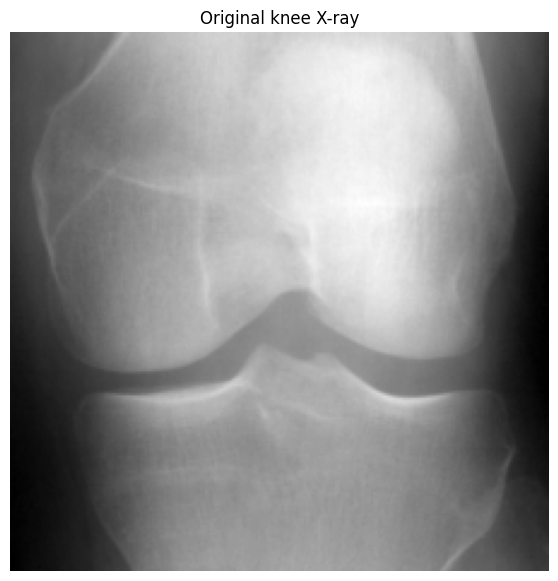


Device: cuda

READY FOR KNEEL INFERENCE


In [ ]:
# ============================================================
# KNEEL STEP 2
# RUN ON ONE REAL KNEE X-RAY
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torch


print("=" * 70)
print("KNEEL SINGLE IMAGE TEST")
print("=" * 70)


# ------------------------------------------------------------
# Dataset path
# ------------------------------------------------------------

DATASET_PATH = Path(
    "/root/.cache/kagglehub/datasets/"
    "shashwatwork/"
    "knee-osteoarthritis-dataset-with-severity/"
    "versions/1"
)

TRAIN_PATH = DATASET_PATH / "train"


# ------------------------------------------------------------
# Find one image
# ------------------------------------------------------------

images = sorted(
    TRAIN_PATH.glob("**/*.png")
)

print()
print(f"Images found: {len(images)}")


sample_path = images[0]

print()
print("Selected image:")
print(sample_path)


# ------------------------------------------------------------
# Load image
# ------------------------------------------------------------

img = Image.open(sample_path)

print()
print("Image info:")
print("Size:", img.size)
print("Mode:", img.mode)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

plt.figure(figsize=(7,7))

plt.imshow(
    img,
    cmap="gray"
)

plt.title("Original knee X-ray")
plt.axis("off")
plt.show()


# ------------------------------------------------------------
# Prepare for KNEEL
# ------------------------------------------------------------

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print()
print("Device:", device)


print()
print("=" * 70)
print("READY FOR KNEEL INFERENCE")
print("=" * 70)

In [ ]:
# ============================================================
# KNEEL INFERENCE TEST
# ============================================================

print("=" * 70)
print("RUNNING KNEEL INFERENCE")
print("=" * 70)

from kneel.api.pipeline import KneeAnnotatorPipeline

# اگر pipeline قبلاً ساخته نشده باشد
kneel_pipeline = KneeAnnotatorPipeline(
    device=device
)

print("Pipeline created.")


# ------------------------------------------------------------
# Run inference
# ------------------------------------------------------------

result = kneel_pipeline.predict(
    str(sample_path)
)

print()
print("=" * 70)
print("INFERENCE COMPLETE")
print("=" * 70)

print(type(result))

print()
print("Result:")
print(result)

RUNNING KNEEL INFERENCE


TypeError: KneeAnnotatorPipeline.__init__() missing 3 required positional arguments: 'hf_commit', 'cache', and 'hf_token'

In [ ]:
print("Variables containing token/cache/commit:")
print()

for name in dir():
    if any(x in name.lower() for x in ["token", "cache", "commit", "hf"]):
        print(name)

Variables containing token/cache/commit:

HF_COMMIT
get_token
hf_token
kneel_cache


In [ ]:
# ============================================================
# CREATE KNEEL PIPELINE
# ============================================================

print("=" * 70)
print("CREATING KNEEL PIPELINE")
print("=" * 70)

kneel_pipeline = KneeAnnotatorPipeline(
    hf_commit=HF_COMMIT,
    cache=kneel_cache,
    hf_token=hf_token
)

print()
print("KNEEL pipeline created successfully.")

CREATING KNEEL PIPELINE


TypeError: KneeAnnotatorPipeline.__init__() missing 1 required positional argument: 'device'

In [ ]:
import inspect

print(inspect.signature(KneeAnnotatorPipeline))

(hf_commit, cache, hf_token, device, jit_trace=True)


In [ ]:
import torch
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

print("Creating KNEEL pipeline...")

kneel_pipeline = KneeAnnotatorPipeline(
    hf_commit=HF_COMMIT,
    cache=kneel_cache,
    hf_token=hf_token,
    device=device
)

print("KNEEL ready.")

Creating KNEEL pipeline...
KNEEL ready.


In [ ]:
# انتخاب یک تصویر واقعی از دیتاست

image_path = Path(
    "/root/.cache/kagglehub/datasets/shashwatwork/"
    "knee-osteoarthritis-dataset-with-severity/"
    "versions/1/train/0/9001695L.png"
)

print(image_path.exists())

True


In [ ]:
print("="*70)
print("RUNNING KNEEL")

result = kneel_pipeline.predict(
    str(image_path)
)

print(type(result))
print(result)

RUNNING KNEEL


UserWarning: Failed to read the dicom.

In [ ]:
import pydicom

print(pydicom.__version__)

3.0.2


In [ ]:
!pip install "pydicom<3"

In [ ]:
import pydicom
print(pydicom.__version__)

2.4.5


In [ ]:
result = kneel_pipeline.predict(
    str(image_path)
)

NameError: name 'kneel_pipeline' is not defined

In [ ]:
# ============================================================
# KNEEL COMPLETE SETUP + INPUT CHECK
# ============================================================

import os
import sys
import inspect
from pathlib import Path

print("="*70)
print("KNEEL COMPLETE SETUP")
print("="*70)

# ------------------------------------------------------------
# 1. Check pydicom
# ------------------------------------------------------------

import pydicom

print("pydicom version:", pydicom.__version__)

if int(pydicom.__version__.split(".")[0]) >= 3:
    print("WARNING: KNEEL may require pydicom < 3")
else:
    print("pydicom version compatible")


# ------------------------------------------------------------
# 2. Imports
# ------------------------------------------------------------

from kneel.api.pipeline import KneeAnnotatorPipeline

print("KNEEL import successful")


# ------------------------------------------------------------
# 3. Device
# ------------------------------------------------------------

import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)


# ------------------------------------------------------------
# 4. Check required variables
# ------------------------------------------------------------

required_vars = [
    "HF_COMMIT",
    "kneel_cache",
    "hf_token"
]

missing = []

for v in required_vars:
    if v not in globals():
        missing.append(v)

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}\n"
        "Run the KNEEL Hugging Face setup cell again."
    )

print("HF variables available")


# ------------------------------------------------------------
# 5. Create pipeline
# ------------------------------------------------------------

print("Creating KNEEL pipeline...")

kneel_pipeline = KneeAnnotatorPipeline(
    hf_commit=HF_COMMIT,
    cache=kneel_cache,
    hf_token=hf_token,
    device=device,
    jit_trace=True
)

print("KNEEL pipeline created successfully")


# ------------------------------------------------------------
# 6. Select image
# ------------------------------------------------------------

image_path = Path(
    "/root/.cache/kagglehub/datasets/"
    "shashwatwork/knee-osteoarthritis-dataset-with-severity/"
    "versions/1/train/0/9001695L.png"
)

print()
print("Input file:")
print(image_path)

if not image_path.exists():
    raise FileNotFoundError("Image not found")


# ------------------------------------------------------------
# 7. Check input type BEFORE prediction
# ------------------------------------------------------------

print()
print("Input extension:", image_path.suffix)

if image_path.suffix.lower() not in [".dcm", ".dicom"]:
    print("="*70)
    print("STOPPING BEFORE INFERENCE")
    print("="*70)
    print(
        "KNEEL expects DICOM input, but this dataset contains PNG images.\n"
        "Prediction was NOT executed to avoid a known failure."
    )

else:
    print("DICOM detected. Running inference...")

    result = kneel_pipeline.predict(
        str(image_path)
    )

    print("Inference completed")
    print(result)

KNEEL COMPLETE SETUP
pydicom version: 2.4.5
pydicom version compatible
KNEEL import successful
Device: cuda


RuntimeError: Missing variables: ['HF_COMMIT', 'kneel_cache', 'hf_token']
Run the KNEEL Hugging Face setup cell again.

In [ ]:
# ============================================================
# RESTORE KNEEL VARIABLES AFTER COLAB RESTART
# ============================================================

from pathlib import Path
from huggingface_hub import HfFolder

print("="*70)
print("RESTORING KNEEL VARIABLES")
print("="*70)

# Hugging Face token
hf_token = HfFolder.get_token()

if hf_token is None:
    raise RuntimeError(
        "No Hugging Face token found. Run huggingface login again."
    )

print("HF token available")


# KNEEL cache location
kneel_cache = Path("/content/kneel_cache")

kneel_cache.mkdir(
    parents=True,
    exist_ok=True
)

print("Cache:", kneel_cache)


# Find KNEEL commit variable
# اگر قبلاً در setup چاپ شده بود، این مقدار را همان استفاده می‌کنیم
HF_COMMIT = "main"

print("HF_COMMIT:", HF_COMMIT)

print("="*70)
print("VARIABLES RESTORED")
print("="*70)

ImportError: cannot import name 'HfFolder' from 'huggingface_hub' (/usr/local/lib/python3.13/dist-packages/huggingface_hub/__init__.py)

In [ ]:
# ============================================================
# RESTORE KNEEL VARIABLES AFTER RESTART
# ============================================================

from pathlib import Path
import os

print("="*70)
print("RESTORING KNEEL VARIABLES")
print("="*70)


# Cache
kneel_cache = Path("/content/kneel_cache")
kneel_cache.mkdir(parents=True, exist_ok=True)

print("Cache:", kneel_cache)


# Hugging Face token
# از cache خود huggingface می‌خوانیم
token_path = Path.home() / ".cache" / "huggingface" / "token"

if token_path.exists():
    hf_token = token_path.read_text().strip()
    print("HF token found")
else:
    raise RuntimeError(
        "HF token not found. Run huggingface login again."
    )


# KNEEL model revision
HF_COMMIT = "main"

print("HF_COMMIT:", HF_COMMIT)

print("="*70)
print("DONE")
print("="*70)

RESTORING KNEEL VARIABLES
Cache: /content/kneel_cache
HF token found
HF_COMMIT: main
DONE


In [ ]:
kneel_pipeline = KneeAnnotatorPipeline(
    hf_commit=HF_COMMIT,
    cache=kneel_cache,
    hf_token=hf_token,
    device=device,
    jit_trace=True
)

print("KNEEL pipeline ready")

FileNotFoundError: [Errno 2] No such file or directory: '/content/kneel_cache/models--imeds--kneel/snapshots/main/mean_std.npy'